# Régression · Combien vaut cette voiture ?

[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josephazar/ELC2-Introduction-IA-2026/blob/main/seance-3/ia-elc2/04-regression.ipynb)

**ELC2 · Introduction au machine learning · Séance 3**

Nathalie, de **Comtoise Auto Occasion**, voudrait **estimer le prix** d'une voiture dès qu'elle
entre dans le stock. La réponse à deviner est **un nombre** (un prix en euros) : c'est un problème
de **régression**.

Le fichier du jour est **propre** : la préparation (doublons, cases vides, valeurs aberrantes) a été faite
en séance 1 et revue en séance 2. On se concentre sur la régression. Ce notebook :

1. regarde les données ;
2. calcule **une droite à la main** sur 5 voitures, puis la fait calculer à Python sur les 500 ;
3. **mesure l'erreur** (erreur moyenne, RMSE, R²) et la compare à un modèle « bête » ;
4. passe à **plusieurs caractéristiques** à la fois, et lit les **résidus** ;
5. ajoute une **courbe**, et montre ce que veut dire trop de courbure ;
6. liste les pièges, puis compare tous les modèles.

Vous n'avez **rien à écrire** : il suffit d'exécuter les cellules, dans l'ordre, avec
**Maj + Entrée** dans Jupyter (**Exécution → Tout exécuter** sur Google Colab). Sur GitHub, le
notebook s'affiche avec ses résultats : il se lit comme un guide.

## 0. Vérifier que tout est prêt

Cette cellule dit où tourne votre notebook. Sur votre ordinateur, ce doit être le Python du
dossier `.venv` de votre dossier `ia-elc2`. Sur Google Colab, il n'y a rien à vérifier.

In [1]:
import sys
from pathlib import Path

python_utilise = Path(sys.executable)

if "google.colab" in sys.modules:
    print("OK : vous êtes sur Google Colab, il n'y a rien à installer.")
elif ".venv" in python_utilise.parts:
    print("Python utilisé :", ".../" + "/".join(python_utilise.parts[-4:]))
    print("OK : ce notebook tourne dans l'environnement virtuel du cours.")
else:
    print("Python utilisé :", python_utilise)
    print("ATTENTION : ce n'est pas le Python du cours. Relisez le guide d'installation.")

Python utilisé : .../ia-elc2/.venv/bin/python
OK : ce notebook tourne dans l'environnement virtuel du cours.


Le fichier des voitures est-il là ? Sur votre ordinateur, il est dans le dossier `donnees`.
Sur Google Colab, cette cellule le télécharge depuis la page GitHub du cours.

In [2]:
from urllib.request import urlretrieve

fichier = Path("donnees/voitures-comtoise-auto.csv")
if not fichier.exists():
    fichier.parent.mkdir(exist_ok=True)
    urlretrieve("https://raw.githubusercontent.com/josephazar/ELC2-Introduction-IA-2026/main/seance-3/ia-elc2/donnees/voitures-comtoise-auto.csv", fichier)
    print("Fichier téléchargé depuis GitHub.")

print("Données prêtes :", fichier)

Données prêtes : donnees/voitures-comtoise-auto.csv


On charge les bibliothèques, et on règle l'allure des graphiques une fois pour toutes.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
})
BLEU, ORANGE, TURQUOISE, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"

---
# Partie 1 · Les données

## 1. Les voitures de Nathalie

In [4]:
voitures = pd.read_csv("donnees/voitures-comtoise-auto.csv")
voitures.head(8)

,ref,annee,kilometrage,puissance_ch,carburant,etat,prix
0,V-0001,2017,118600,75,Diesel,Bon,3990
1,V-0002,2011,142900,110,Essence,Correct,1800
2,V-0003,2021,46800,110,Diesel,Bon,9030
3,V-0004,2023,32200,75,Hybride,Bon,10800
4,V-0005,2021,70300,110,Essence,Bon,9750
5,V-0006,2019,74900,90,Diesel,Bon,6860
6,V-0007,2023,39600,150,Essence,Correct,13990
7,V-0008,2025,17800,150,Hybride,Correct,21960


Une ligne par voiture. Voici ce que veulent dire les colonnes :

| Colonne | Sens | Rôle |
|---|---|---|
| `ref` | numéro de la voiture | identifiant (ne décrit pas la voiture) |
| `annee` | année de la voiture | caractéristique |
| `kilometrage` | kilomètres au compteur | caractéristique |
| `puissance_ch` | puissance en chevaux | caractéristique |
| `carburant` | Essence, Diesel, Hybride, Électrique | caractéristique (texte sans ordre) |
| `etat` | Mauvais, Correct, Bon, Très bon | caractéristique (texte **avec** un ordre) |
| **`prix`** | prix de vente en euros | **la cible**, ce qu'on veut deviner |

In [5]:
voitures.shape

(500, 7)

Le fichier est propre, comme promis : aucune case vide, aucun doublon. Vérifions.

In [6]:
print("cases vides :", voitures.isna().sum().sum())
print("lignes en double :", voitures.duplicated().sum())

cases vides : 0
lignes en double : 0


Une **caractéristique** à fabriquer : l'**âge** de la voiture parle plus que son année de fabrication.
L'âge est ce qu'on appelle une colonne **construite** à partir d'une autre.

In [7]:
voitures["age"] = 2026 - voitures["annee"]
voitures[["annee", "age", "kilometrage", "puissance_ch", "prix"]].describe().round(0)

,annee,age,kilometrage,puissance_ch,prix
count,500.0,500.0,500.0,500.0,500.0
mean,2020.0,6.0,80538.0,110.0,8920.0
std,3.0,3.0,50653.0,27.0,4333.0
min,2011.0,1.0,4300.0,75.0,900.0
25%,2018.0,4.0,42900.0,90.0,5660.0
50%,2020.0,6.0,70500.0,110.0,8275.0
75%,2022.0,8.0,105375.0,130.0,11752.0
max,2025.0,15.0,266900.0,180.0,23250.0


## 2. Regarder avant de modéliser

Avant de calculer quoi que ce soit, on **dessine** : un nuage de points du prix contre chaque caractéristique.

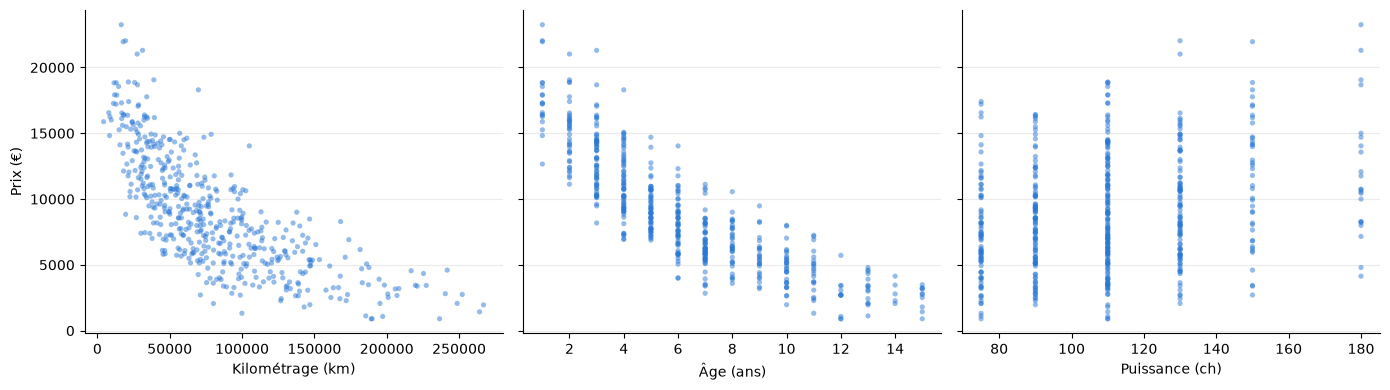

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, colonne, titre in zip(axes, ["kilometrage", "age", "puissance_ch"], ["Kilométrage (km)", "Âge (ans)", "Puissance (ch)"]):
    ax.scatter(voitures[colonne], voitures["prix"], s=14, color=BLEU, alpha=0.5, edgecolor="none")
    ax.set_xlabel(titre)
axes[0].set_ylabel("Prix (€)")
plt.tight_layout()
plt.show()

Ce qu'on voit :

- plus la voiture a **roulé** ou plus elle est **vieille**, moins elle vaut ;
- la **puissance** joue peu, et moins nettement ;
- le prix **en fonction de l'âge** ne descend pas en ligne droite : il chute vite les premières années, puis ralentit.

On mesure cela avec la **corrélation** (séance 1) : proche de −1 ou de +1, deux colonnes bougent ensemble.

In [9]:
voitures[["age", "kilometrage", "puissance_ch", "prix"]].corr().round(2)

,age,kilometrage,puissance_ch,prix
age,1.00,0.87,0.01,-0.85
kilometrage,0.87,1.00,0.05,-0.74
puissance_ch,0.01,0.05,1.00,0.27
prix,-0.85,-0.74,0.27,1.00


Deux choses à noter :

- le prix est lié à l'âge (−0,85) et au kilométrage (−0,74) ;
- **l'âge et le kilométrage sont eux-mêmes très liés (0,87)** : une voiture âgée a beaucoup roulé. Ce sont des
  **colonnes jumelles**, comme en séance 1. Nous y reviendrons.

---
# Partie 2 · Une droite, d'abord à la main

## 3. Cinq voitures, une droite

Pour comprendre ce que fait un ordinateur, on le fait d'abord **à la main**, comme en cours, sur **5 voitures aux
chiffres arrondis** : le kilométrage est en dizaines de milliers de km, le prix en milliers d'euros.

In [10]:
x5 = np.array([2, 4, 6, 8, 10])      # kilométrage, en dizaines de milliers de km
y5 = np.array([14, 13, 11, 10, 7])   # prix, en milliers d'euros

pd.DataFrame({"voiture": list("ABCDE"), "x (km)": x5, "y (prix)": y5})

,voiture,x (km),y (prix)
0,A,2,14
1,B,4,13
2,C,6,11
3,D,8,10
4,E,10,7


Une droite s'écrit **prix = a × kilométrage + b**. Pour trouver `a` (la pente) et `b` (le point de départ),
on suit les étapes du cours.

**Étape 1 : les moyennes.**

In [11]:
x_moy = x5.mean()
y_moy = y5.mean()
print("moyenne du kilométrage :", x_moy)
print("moyenne du prix        :", y_moy)

moyenne du kilométrage : 6.0
moyenne du prix        : 11.0


**Étape 2 : la pente `a`.** La pente répond à la question : *de combien le prix change-t-il quand le kilométrage augmente de 1 ?*
On la calcule en trois temps, que voici.

1. **Les écarts à la moyenne.** On mesure chaque voiture par rapport à la voiture « moyenne » (6 ; 11) : de combien
   s'écarte-t-elle en kilométrage (x − moyenne de x), et en prix (y − moyenne de y) ?
2. **Le produit des deux écarts.** Si les deux vont dans le **même sens**, le produit est positif ; en **sens contraire**,
   il est négatif. La **somme des produits** dit donc dans quel sens et avec quelle force x et y varient ensemble.
3. **La division.** On divise par la **somme des carrés des écarts en x**, qui mesure l'**étalement** des kilométrages. Cela ramène
   le lien à **une unité** de kilométrage : c'est bien ce qu'est une pente.

La formule : **a = Σ (x − x̄) × (y − ȳ) / Σ (x − x̄)²**, où Σ se lit « somme de » (on additionne le calcul de chaque voiture).
Elle n'est pas devinée : c'est la formule qui donne la **somme des erreurs au carré la plus petite**, le fond de la « cuvette »
du cours. On la démontre en cherchant où cette erreur cesse de descendre (le calcul de dérivées, vu en mathématiques). Ici,
nous l'**admettons** et nous l'appliquons.

In [12]:
calcul = pd.DataFrame({
    "voiture": list("ABCDE"),
    "x": x5,
    "y": y5,
    "x - moyenne": x5 - x_moy,
    "y - moyenne": y5 - y_moy,
    "produit": (x5 - x_moy) * (y5 - y_moy),
    "carré de (x - moyenne)": (x5 - x_moy) ** 2,
})
calcul

,voiture,x,y,x - moyenne,y - moyenne,produit,carré de (x - moyenne)
0,A,2,14,-4.0,3.0,-12.0,16.0
1,B,4,13,-2.0,2.0,-4.0,4.0
2,C,6,11,0.0,0.0,0.0,0.0
3,D,8,10,2.0,-1.0,-2.0,4.0
4,E,10,7,4.0,-4.0,-16.0,16.0


In [13]:
somme_produits = calcul["produit"].sum()
somme_carres = calcul["carré de (x - moyenne)"].sum()
a = somme_produits / somme_carres

print("somme des produits :", somme_produits)
print("somme des carrés   :", somme_carres)
print("pente a            :", a)

somme des produits : -34.0
somme des carrés   : 40.0
pente a            : -0.85


**Étape 3 : le point de départ `b`.** La meilleure droite passe toujours par le **point moyen** (6 ; 11). Pourquoi ? Si elle
passait au-dessus du nuage, presque toutes les erreurs seraient du même côté : en la descendant un peu, on ferait baisser
la somme des carrés. La meilleure droite **équilibre ses erreurs**, et cela n'arrive que si elle passe par le point moyen.

Comme elle passe par (x̄ ; ȳ), on a ȳ = a × x̄ + b. On isole `b` : **b = ȳ − a × x̄**.

In [14]:
b = y_moy - a * x_moy
print(f"prix = {a:.2f} × kilométrage + {b:.1f}")

prix = -0.85 × kilométrage + 16.1


Lecture : chaque tranche de 10 000 km en plus fait perdre **0,85 millier d'euros, soit 850 €**. Une voiture à 0 km
vaudrait **16 100 €**.

**Vérification.** Python sait le faire seul : `LinearRegression`. Il doit trouver **exactement** les mêmes nombres.

In [15]:
from sklearn.linear_model import LinearRegression

modele_5 = LinearRegression()
modele_5.fit(x5.reshape(-1, 1), y5)       # scikit-learn veut un tableau à deux dimensions : une colonne par caractéristique

print("pente a :", round(modele_5.coef_[0], 2))
print("départ b :", round(modele_5.intercept_, 2))

pente a : -0.85
départ b : 16.1


Même résultat : `LinearRegression` n'a rien de magique, il fait ce calcul (en plus général).

**Pourquoi cette droite-là ?** Parce qu'elle donne la **somme des erreurs au carré la plus petite**. Comparons
trois droites : celle qu'on vient de trouver, et deux autres tracées à l'œil.

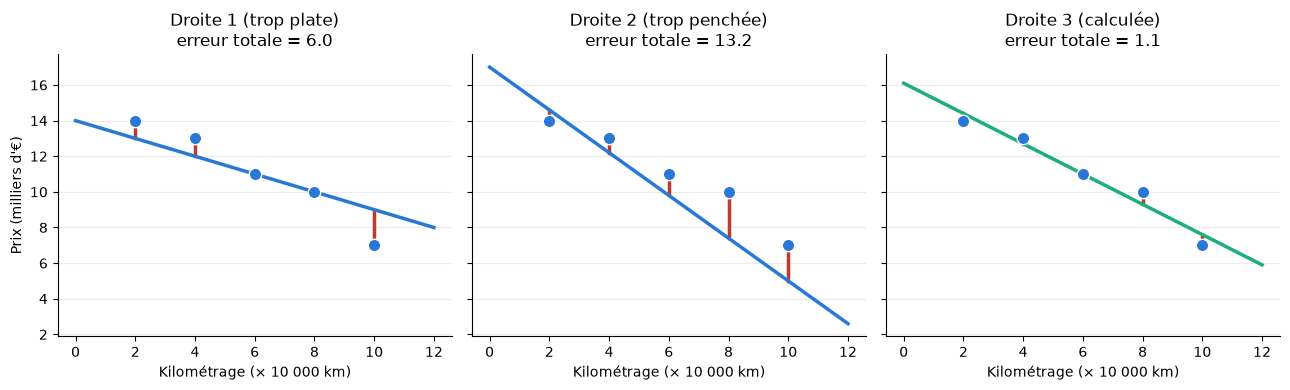

In [16]:
def erreur_totale(a, b):
    """Somme des erreurs au carré de la droite prix = a × km + b sur les 5 voitures."""
    prediction = a * x5 + b
    return ((y5 - prediction) ** 2).sum()

droites = {"Droite 1 (trop plate)": (-0.5, 14.0),
           "Droite 2 (trop penchée)": (-1.2, 17.0),
           "Droite 3 (calculée)": (a, b)}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (nom, (a_, b_)) in zip(axes, droites.items()):
    prediction = a_ * x5 + b_
    for xi, yi, pi in zip(x5, y5, prediction):
        ax.plot([xi, xi], [yi, pi], color="#c0392b", lw=2.5)          # l'erreur de chaque voiture
    ax.plot([0, 12], [b_, 12 * a_ + b_], color=TURQUOISE if "calculée" in nom else BLEU, lw=2.5)
    ax.scatter(x5, y5, s=80, color=BLEU, zorder=5, edgecolor="white")
    ax.set_title(f"{nom}\nerreur totale = {erreur_totale(a_, b_):.1f}")
    ax.set_xlabel("Kilométrage (× 10 000 km)")
axes[0].set_ylabel("Prix (milliers d'€)")
plt.tight_layout()
plt.show()

Les traits rouges sont les **erreurs** (l'écart vertical entre la voiture et la droite). La droite calculée a la plus
petite somme : **1,1**, contre 6,0 et 13,2.

## 4. La même chose sur les 500 voitures

Avec 500 voitures, plus question de calculer à la main, mais l'idée est identique. Une seule précaution, rappel de la
séance 2 : on **découpe** les données en un paquet pour **apprendre** (le *train*, 80 %) et un paquet pour
**examiner** (le *test*, 20 %), que le modèle ne voit jamais pendant l'apprentissage.

In [17]:
from sklearn.model_selection import train_test_split

X = voitures[["kilometrage"]]          # une seule caractéristique, donc une seule colonne (deux crochets)
y = voitures["prix"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("voitures pour apprendre :", len(X_train))
print("voitures pour l'examen  :", len(X_test))

voitures pour apprendre : 400
voitures pour l'examen  : 100


In [18]:
droite = LinearRegression()
droite.fit(X_train, y_train)

print(f"prix = {droite.coef_[0]:.4f} × kilométrage + {droite.intercept_:.0f}")
print(f"soit {droite.coef_[0] * 10000:.0f} € tous les 10 000 km")

prix = -0.0619 × kilométrage + 13882
soit -619 € tous les 10 000 km


Dessinons la droite par-dessus les voitures.

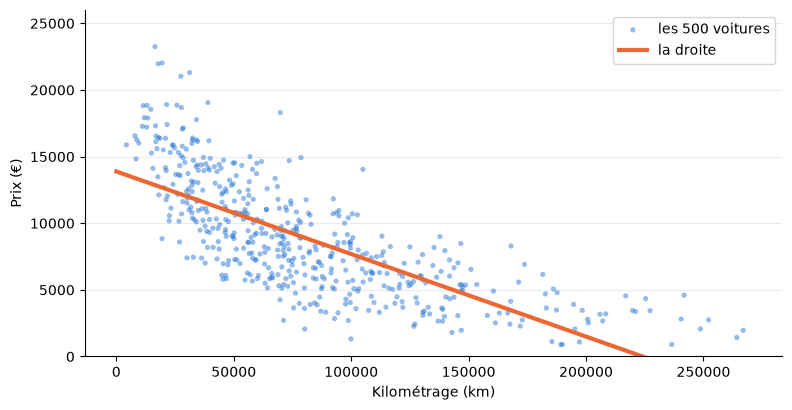

In [19]:
plt.figure(figsize=(9, 4.5))
plt.scatter(X["kilometrage"], y, s=14, color=BLEU, alpha=0.5, edgecolor="none", label="les 500 voitures")
km = pd.DataFrame({"kilometrage": [0, 270000]})
plt.plot(km["kilometrage"], droite.predict(km), color=ORANGE, lw=3, label="la droite")
plt.xlabel("Kilométrage (km)")
plt.ylabel("Prix (€)")
plt.ylim(0, 26000)
plt.legend()
plt.show()

**Faire une prédiction.** Quel prix pour une voiture à 70 000 km ? Et à 250 000 km ?

In [20]:
nouvelles = pd.DataFrame({"kilometrage": [70000, 250000]})
droite.predict(nouvelles).round(0)

array([ 9546., -1605.])

Le premier prix est raisonnable. Le second est **négatif** : à 250 000 km, la droite annonce que la voiture vaut
moins que rien. C'est l'**extrapolation** : loin des données, le modèle ne sait plus. Un modèle n'est valable que
**là où il a vu des exemples** (ici, jusqu'à environ 200 000 km).

---
# Partie 3 · Mesurer l'erreur

## 5. Erreur moyenne, RMSE, R²

Une prédiction n'est jamais exacte. Pour savoir si la droite est bonne, on regarde, **sur le test**, de combien elle
se trompe.

In [21]:
y_predit = droite.predict(X_test)

comparaison = pd.DataFrame({
    "kilométrage": X_test["kilometrage"],
    "prix réel": y_test,
    "prix prédit": y_predit.round(0),
})
comparaison["erreur (réel − prédit)"] = comparaison["prix réel"] - comparaison["prix prédit"]
comparaison.head(8)

,kilométrage,prix réel,prix prédit,erreur (réel − prédit)
361,37300,13940,11572.0,2368.0
73,56400,12080,10388.0,1692.0
374,56600,13110,10376.0,2734.0
155,128500,7080,5922.0,1158.0
104,82500,3900,8772.0,-4872.0
394,53600,10720,10562.0,158.0
377,82100,7770,8796.0,-1026.0
124,99200,8540,7737.0,803.0


Trois mesures résument ces erreurs.

- **L'erreur moyenne** (MAE) : la moyenne des erreurs **sans leur signe**. C'est « de combien je me trompe en moyenne », en euros.
- **Le RMSE** : on met les erreurs **au carré**, on en fait la **moyenne**, puis on prend la **racine carrée** pour revenir aux euros.
  Les **grosses erreurs comptent davantage**.
- **Le R²** : `1 − (erreurs au carré du modèle) / (erreurs au carré du modèle bête)`. Le rapport est la part d'erreur qui **reste** ;
  1 moins cette part est la part d'erreur **supprimée**. 1 = parfait, 0 = pas mieux que le modèle bête.

Le modèle « bête » annonce **toujours le prix moyen**, quelle que soit la voiture. Il sert de référence.

In [22]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

resultats = []          # on garde tous les résultats, pour le tableau final


def evaluer(nom, y_reel, y_predit):
    """Calcule les trois mesures sur le test, les affiche et les range pour le tableau final."""
    ligne = {"modèle": nom,
             "erreur moyenne (€)": round(mean_absolute_error(y_reel, y_predit)),
             "RMSE (€)": round(root_mean_squared_error(y_reel, y_predit)),
             "R²": round(r2_score(y_reel, y_predit), 2)}
    resultats.append(ligne)
    return pd.DataFrame([ligne]).set_index("modèle")


bete = DummyRegressor(strategy="mean").fit(X_train, y_train)
print("le modèle bête annonce toujours :", round(bete.predict(X_test)[0]), "€")
evaluer("« Bête » : toujours la moyenne", y_test, bete.predict(X_test))

le modèle bête annonce toujours : 8824 €


,erreur moyenne (€),RMSE (€),R²
modèle,,,
« Bête » : toujours la moyenne,3590,4258,-0.01


In [23]:
evaluer("Droite sur le kilométrage", y_test, droite.predict(X_test))

,erreur moyenne (€),RMSE (€),R²
modèle,,,
Droite sur le kilométrage,2160,2640,0.61


La droite se trompe d'environ **2 160 € en moyenne** (le modèle bête : 3 590 €), et son **R² vaut 0,61** : elle fait
61 % du chemin entre le modèle bête et la perfection. C'est un début, pas une fin.

Un graphique aide : le **prix prédit contre le prix réel**. Un modèle parfait aligne tous les points sur la diagonale.

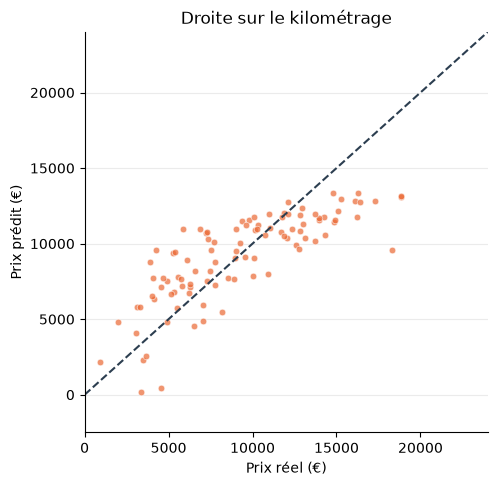

In [24]:
def tracer_reel_predit(y_reel, y_predit, titre, couleur):
    plt.figure(figsize=(5.2, 5.2))
    plt.scatter(y_reel, y_predit, s=22, color=couleur, alpha=0.7, edgecolor="white", linewidth=0.5)
    plt.plot([0, 24000], [0, 24000], color="#2c3e50", lw=1.5, ls="--")        # la diagonale : la perfection
    plt.xlabel("Prix réel (€)")
    plt.ylabel("Prix prédit (€)")
    plt.title(titre)
    plt.xlim(0, 24000)
    plt.ylim(-2500, 24000)
    plt.show()


tracer_reel_predit(y_test, droite.predict(X_test), "Droite sur le kilométrage", ORANGE)

---
# Partie 4 · Plusieurs caractéristiques

## 6. Prédire le prix avec tout ce qu'on sait

Un prix dépend de l'âge, du kilométrage, de la puissance, de l'état, du carburant. La régression **multiple** garde la
même idée, avec **un coefficient par caractéristique** :

**prix = a₁ × âge + a₂ × km + a₃ × puissance + a₄ × état + … + b**

Deux colonnes sont du **texte** : on applique ce qu'on sait depuis la séance 1.

- `etat` a un **ordre** (Mauvais < Correct < Bon < Très bon) : on le code en **0, 1, 2, 3** (ordinal) ;
- `carburant` n'a **pas d'ordre** : on fait une colonne 0/1 par carburant (**one-hot**). On retire la colonne `Essence`,
  qui sert de **référence** : chaque effet se lira « par rapport à une essence ».

In [25]:
voitures["etat_num"] = voitures["etat"].map({"Mauvais": 0, "Correct": 1, "Bon": 2, "Très bon": 3})

colonnes = ["age", "kilometrage", "puissance_ch", "etat_num", "carburant"]
X_multi = pd.get_dummies(voitures[colonnes], columns=["carburant"], dtype=float)
X_multi = X_multi.drop(columns="carburant_Essence")          # l'essence est la référence

X_multi.head()

,age,kilometrage,puissance_ch,etat_num,carburant_Diesel,carburant_Hybride,carburant_Électrique
0,9,118600,75,2,1.0,0.0,0.0
1,15,142900,110,1,0.0,0.0,0.0
2,5,46800,110,2,1.0,0.0,0.0
3,3,32200,75,2,0.0,1.0,0.0
4,5,70300,110,2,0.0,0.0,0.0


In [26]:
# même découpage que tout à l'heure : mêmes voitures pour apprendre, mêmes voitures pour l'examen
X_train_m, X_test_m, y_train, y_test = train_test_split(X_multi, y, test_size=0.2, random_state=42)

multiple = LinearRegression()
multiple.fit(X_train_m, y_train)

evaluer("Plusieurs caractéristiques", y_test, multiple.predict(X_test_m))

,erreur moyenne (€),RMSE (€),R²
modèle,,,
Plusieurs caractéristiques,1104,1486,0.88


Beaucoup mieux : l'erreur moyenne tombe à environ **1 100 €** et le **R² monte à 0,88**.

Chaque coefficient dit l'effet d'une caractéristique, **toutes les autres restant égales**. Mettons-les dans des
unités qui parlent (par an, par 10 000 km, par 10 chevaux…).

In [27]:
c = dict(zip(X_multi.columns, multiple.coef_))

effets = pd.Series({
    "1 an de plus": c["age"],
    "10 000 km de plus": c["kilometrage"] * 10000,
    "10 ch de plus": c["puissance_ch"] * 10,
    "1 niveau d'état de mieux": c["etat_num"],
    "Diesel (au lieu d'essence)": c["carburant_Diesel"],
    "Hybride (au lieu d'essence)": c["carburant_Hybride"],
    "Électrique (au lieu d'essence)": c["carburant_Électrique"],
})
effets.round(0)

1 an de plus                      -985.0
10 000 km de plus                  -58.0
10 ch de plus                      485.0
1 niveau d'état de mieux           976.0
Diesel (au lieu d'essence)         458.0
Hybride (au lieu d'essence)       1647.0
Électrique (au lieu d'essence)    2719.0
dtype: float64

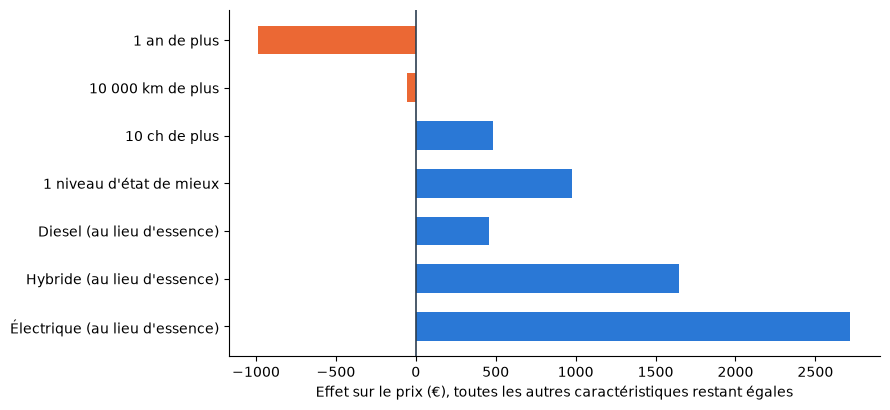

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.2))
couleurs = [BLEU if v >= 0 else ORANGE for v in effets[::-1]]
ax.barh(effets.index[::-1], effets[::-1], color=couleurs, height=0.6)
ax.axvline(0, color="#2c3e50", lw=1.2)
ax.set_xlabel("Effet sur le prix (€), toutes les autres caractéristiques restant égales")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Lecture :

- **un an de plus** fait perdre environ **985 €** ;
- **un niveau d'état de mieux** fait gagner environ **976 €** ;
- une voiture **électrique** vaut environ **2 700 € de plus** qu'une essence comparable, une **hybride** 1 650 € de plus.

**Mais le kilométrage ne pèse que −58 € par 10 000 km.** Tout à l'heure, la droite sur le kilométrage seul annonçait
−619 €. Le kilométrage serait-il sans importance ? Faisons l'expérience : on **retire l'âge** et on regarde le
kilométrage.

In [29]:
sans_age_train = X_train_m.drop(columns="age")
sans_age_test = X_test_m.drop(columns="age")
modele_sans_age = LinearRegression().fit(sans_age_train, y_train)

position = list(sans_age_train.columns).index("kilometrage")
print(f"Avec l'âge    : {c['kilometrage'] * 10000:.0f} € par 10 000 km")
print(f"Sans l'âge    : {modele_sans_age.coef_[position] * 10000:.0f} € par 10 000 km")
print("corrélation âge / kilométrage :", round(voitures['age'].corr(voitures['kilometrage']), 2))

Avec l'âge    : -58 € par 10 000 km
Sans l'âge    : -610 € par 10 000 km
corrélation âge / kilométrage : 0.87


Sans l'âge, le kilométrage reprend le rôle de l'âge : son effet passe de −58 € à **−610 €** par 10 000 km, presque la valeur de la droite simple (−619 €). L'âge et le kilométrage
racontent **presque la même histoire** : quand le modèle connaît déjà l'âge, le kilométrage lui apprend peu de plus.

Retenez : **un coefficient se lit « toutes choses égales par ailleurs »**, jamais tout seul, et **ne dit pas qui est
la cause** de quoi.

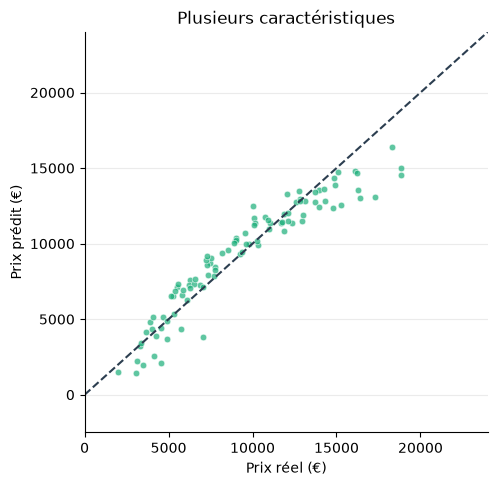

In [30]:
tracer_reel_predit(y_test, multiple.predict(X_test_m), "Plusieurs caractéristiques", TURQUOISE)

## 7. Regarder les résidus

Un **résidu** est l'erreur d'une voiture : prix réel − prix prédit. Si le modèle a tout compris, les résidus sont
**répartis au hasard autour de zéro**. Si les résidus **dessinent une forme**, le modèle rate quelque chose.

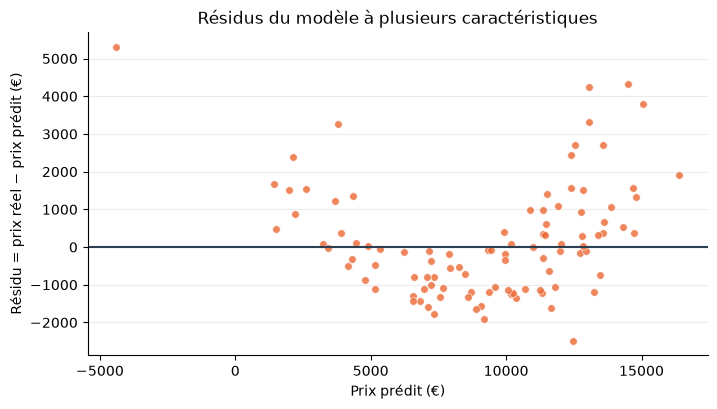

In [31]:
residus = y_test - multiple.predict(X_test_m)

plt.figure(figsize=(8, 4.2))
plt.scatter(multiple.predict(X_test_m), residus, s=30, color=ORANGE, alpha=0.8, edgecolor="white", linewidth=0.5)
plt.axhline(0, color="#2c3e50", lw=1.5)
plt.xlabel("Prix prédit (€)")
plt.ylabel("Résidu = prix réel − prix prédit (€)")
plt.title("Résidus du modèle à plusieurs caractéristiques")
plt.show()

Les points dessinent une **courbe** : positifs aux deux bouts, négatifs au milieu. Le modèle est trop **droit** : il
a manqué la **courbure** de l'âge (une voiture perd beaucoup de valeur les premières années, puis de moins en moins).

Le remède le plus simple : ajouter **l'âge au carré** comme une caractéristique de plus.

In [32]:
X_multi2 = X_multi.assign(age_carre=voitures["age"] ** 2)
X_train_2, X_test_2, y_train, y_test = train_test_split(X_multi2, y, test_size=0.2, random_state=42)

multiple_courbe = LinearRegression().fit(X_train_2, y_train)
evaluer("Plusieurs caractéristiques + âge au carré", y_test, multiple_courbe.predict(X_test_2))

,erreur moyenne (€),RMSE (€),R²
modèle,,,
Plusieurs caractéristiques + âge au carré,658,929,0.95


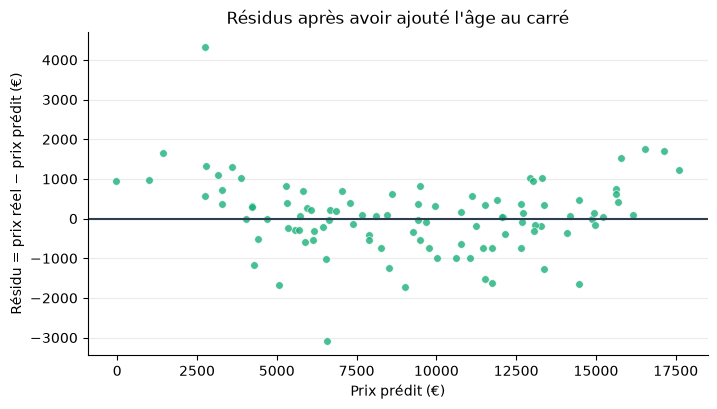

In [33]:
residus_2 = y_test - multiple_courbe.predict(X_test_2)

plt.figure(figsize=(8, 4.2))
plt.scatter(multiple_courbe.predict(X_test_2), residus_2, s=30, color=TURQUOISE, alpha=0.8, edgecolor="white", linewidth=0.5)
plt.axhline(0, color="#2c3e50", lw=1.5)
plt.xlabel("Prix prédit (€)")
plt.ylabel("Résidu = prix réel − prix prédit (€)")
plt.title("Résidus après avoir ajouté l'âge au carré")
plt.show()

Les résidus sont maintenant **au hasard** autour de zéro, et le **R² passe de 0,88 à 0,95** : l'erreur moyenne
tombe à environ **660 €**.

Ajouter l'âge au carré est le principe de la **régression polynomiale**. Regardons-la de près.

---
# Partie 5 · Quand la droite ne suffit plus

## 8. Une courbe sur l'âge

La régression **polynomiale** ajoute les puissances d'une caractéristique (âge, âge², âge³…) : la droite devient
**courbe**. On l'écrit avec `PolynomialFeatures`, dans une chaîne d'étapes (`make_pipeline`) :
standardiser l'âge, ajouter ses puissances, ajuster la droite.

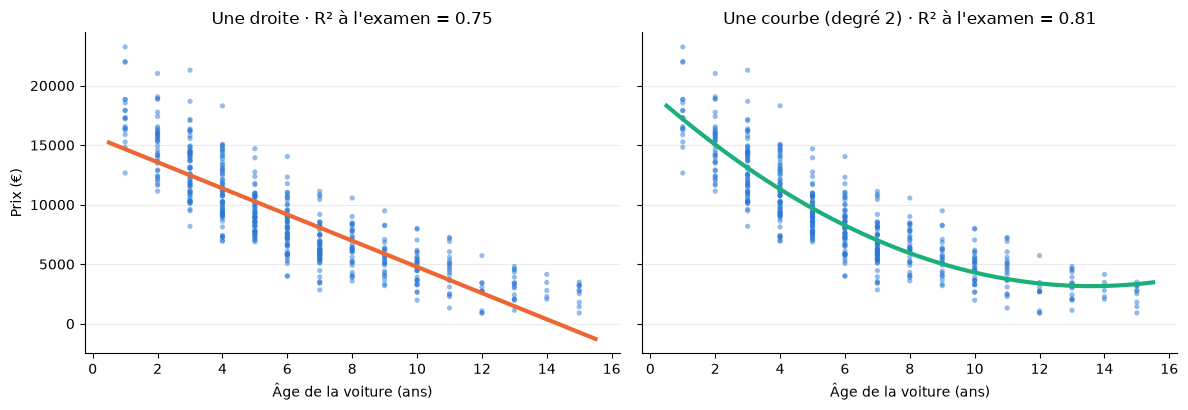

In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

X_age = voitures[["age"]]
X_train_a, X_test_a, y_train, y_test = train_test_split(X_age, y, test_size=0.2, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
ages = pd.DataFrame({"age": np.linspace(0.5, 15.5, 200)})
for ax, degre, titre, couleur in [(axes[0], 1, "Une droite", ORANGE), (axes[1], 2, "Une courbe (degré 2)", TURQUOISE)]:
    modele = make_pipeline(StandardScaler(), PolynomialFeatures(degre), LinearRegression())
    modele.fit(X_train_a, y_train)
    ax.scatter(voitures["age"], voitures["prix"], s=14, color=BLEU, alpha=0.5, edgecolor="none")
    ax.plot(ages["age"], modele.predict(ages), color=couleur, lw=3)
    ax.set_title(f"{titre} · R² à l'examen = {modele.score(X_test_a, y_test):.2f}")
    ax.set_xlabel("Âge de la voiture (ans)")
axes[0].set_ylabel("Prix (€)")
plt.tight_layout()
plt.show()

La courbe de degré 2 suit mieux le nuage : le R² à l'examen passe de **0,75** (droite) à **0,81**.
Faut-il aller plus loin, avec un degré 5, 10, 20 ?

## 9. Trop de courbure : le sur-apprentissage

Rappel de la séance 2 : un modèle **trop simple** rate le fond, un modèle **trop souple** apprend les exercices par
cœur et se trompe à l'examen. Pour **voir** l'effet, on ne garde que **36 voitures** (avec peu de points, l'excès de
souplesse saute aux yeux) et on compare les degrés 1, 2 et 10.

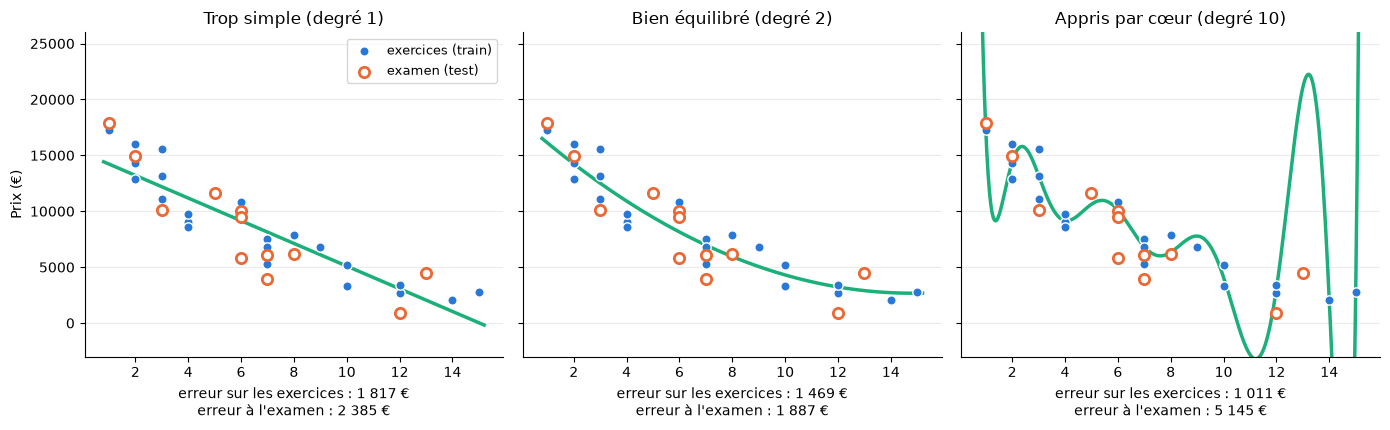

In [35]:
petit = voitures.sample(36, random_state=1)
Xp_train, Xp_test, yp_train, yp_test = train_test_split(petit[["age"]], petit["prix"], test_size=0.33, random_state=13)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
ages = pd.DataFrame({"age": np.linspace(petit["age"].min() - 0.2, petit["age"].max() + 0.2, 300)})
for ax, degre, titre in [(axes[0], 1, "Trop simple"), (axes[1], 2, "Bien équilibré"), (axes[2], 10, "Appris par cœur")]:
    modele = make_pipeline(StandardScaler(), PolynomialFeatures(degre), LinearRegression())
    modele.fit(Xp_train, yp_train)
    erreur_train = root_mean_squared_error(yp_train, modele.predict(Xp_train))
    erreur_test = root_mean_squared_error(yp_test, modele.predict(Xp_test))
    ax.scatter(Xp_train["age"], yp_train, s=45, color=BLEU, edgecolor="white", label="exercices (train)", zorder=4)
    ax.scatter(Xp_test["age"], yp_test, s=55, facecolor="white", edgecolor=ORANGE, linewidth=2, label="examen (test)", zorder=5)
    ax.plot(ages["age"], modele.predict(ages), color=TURQUOISE, lw=2.5)
    ax.set_ylim(-3000, 26000)
    ax.set_title(f"{titre} (degré {degre})")
    ax.set_xlabel(f"erreur sur les exercices : {erreur_train:,.0f} €\nerreur à l'examen : {erreur_test:,.0f} €".replace(",", " "))
axes[0].legend(loc="upper right", fontsize=9)
axes[0].set_ylabel("Prix (€)")
plt.tight_layout()
plt.show()

À droite, la courbe passe **près de tous les points d'entraînement** (erreur de 1 011 €, la plus basse), mais elle
fait de grands détours entre eux : à l'examen, l'erreur monte à **5 145 €**. C'est le **sur-apprentissage**.

Pour choisir le degré, on regarde l'erreur **sur les exercices** et **à l'examen**, pour chaque degré. Le résultat dépend un peu
du découpage ; on le **répète 300 fois** sur des découpages différents et on fait la moyenne.

In [36]:
degres = range(1, 9)
erreurs_train = np.zeros(len(degres))
erreurs_test = np.zeros(len(degres))
tirages = 300

for graine in range(tirages):
    A_train, A_test, b_train, b_test = train_test_split(petit[["age"]], petit["prix"], test_size=0.33, random_state=graine)
    for i, degre in enumerate(degres):
        m = make_pipeline(StandardScaler(), PolynomialFeatures(degre), LinearRegression()).fit(A_train, b_train)
        erreurs_train[i] += root_mean_squared_error(b_train, m.predict(A_train)) / tirages
        erreurs_test[i] += root_mean_squared_error(b_test, m.predict(A_test)) / tirages

pd.DataFrame({"degré": list(degres), "erreur sur les exercices (€)": erreurs_train.round(0),
              "erreur à l'examen (€)": erreurs_test.round(0)}).set_index("degré")

,erreur sur les exercices (€),erreur à l'examen (€)
degré,,
1,1968.0,2189.0
2,1566.0,1766.0
3,1532.0,1820.0
4,1484.0,1893.0
5,1470.0,2196.0
6,1452.0,3256.0
7,1429.0,11275.0
8,1372.0,82442.0


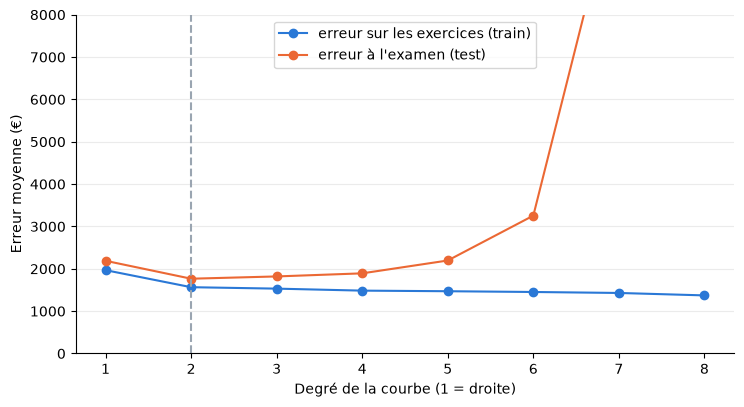

le meilleur degré à l'examen : 2


In [37]:
plt.figure(figsize=(8.5, 4.4))
plt.plot(degres, erreurs_train, color=BLEU, marker="o", label="erreur sur les exercices (train)")
plt.plot(degres, erreurs_test, color=ORANGE, marker="o", label="erreur à l'examen (test)")
meilleur = list(degres)[int(np.argmin(erreurs_test))]
plt.axvline(meilleur, color="#9aa5b1", ls="--")
plt.ylim(0, 8000)
plt.xlabel("Degré de la courbe (1 = droite)")
plt.ylabel("Erreur moyenne (€)")
plt.legend(loc="upper center")
plt.show()
print("le meilleur degré à l'examen :", meilleur)

Sur les exercices, l'erreur ne fait que **baisser**. À l'examen, elle baisse jusqu'au **degré 2**, puis **remonte**
de plus en plus vite : au-delà, le modèle apprend le bruit. **On garde le degré qui minimise l'erreur à l'examen**,
pas à l'entraînement. Règle d'or : **commencer simple**, compliquer seulement si l'examen s'améliore.

---
# Partie 6 · Les pièges, et le bilan

## 10. Une seule erreur de saisie

Retour aux 5 voitures. Que se passe-t-il si **une seule** voiture est mal saisie : 22 000 € au lieu de 7 000 €
pour la voiture E ?

In [38]:
x_faux = np.append(x5, 10)
y_faux = np.append(y5, 22)          # une 6e voiture, avec 100 000 km et 22 000 € : une erreur de saisie

pente_juste = LinearRegression().fit(x5.reshape(-1, 1), y5).coef_[0]
pente_fausse = LinearRegression().fit(x_faux.reshape(-1, 1), y_faux).coef_[0]
print(f"pente sans l'erreur : {pente_juste:.2f}")
print(f"pente avec l'erreur : {pente_fausse:.2f}")

pente sans l'erreur : -0.85
pente avec l'erreur : 0.05


**Une seule** voiture suffit à faire passer la pente de −0,85 à **+0,05** : la droite ne descend plus du tout.
La régression est **très sensible aux valeurs aberrantes** : c'est pourquoi on les traite (z-score, quartiles)
**avant** de modéliser, comme en séance 1.

## 11. Les autres pièges

- **Extrapoler** : ne pas prédire loin des données (le prix négatif de tout à l'heure).
- **Confondre corrélation et causalité** : les ventes de glaces et les noyades montent ensemble en été, mais les glaces ne font
  noyer personne. Un modèle **prédit** ; il ne dit pas **pourquoi**.
- **Se fier à l'entraînement** : un R² de 0,99 sur le train ne vaut rien si le test s'effondre. **Toujours mesurer sur le test.**
- **Lire un coefficient tout seul** : il se lit « toutes choses égales par ailleurs ».

## 12. Le bilan : tous les modèles côte à côte

Tous les modèles ont été mesurés **sur les mêmes 100 voitures de test**.

In [39]:
bilan = pd.DataFrame(resultats).set_index("modèle")
bilan

,erreur moyenne (€),RMSE (€),R²
modèle,,,
« Bête » : toujours la moyenne,3590,4258,-0.01
Droite sur le kilométrage,2160,2640,0.61
Plusieurs caractéristiques,1104,1486,0.88
Plusieurs caractéristiques + âge au carré,658,929,0.95


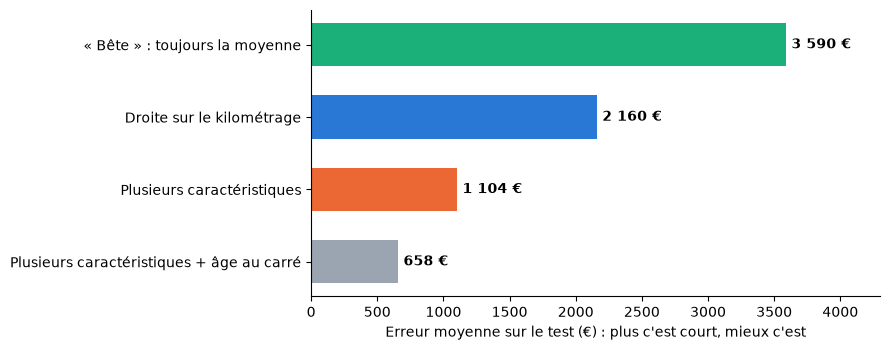

In [40]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(bilan.index[::-1], bilan["erreur moyenne (€)"][::-1], color=[TURQUOISE, BLEU, ORANGE, "#9aa5b1"][::-1], height=0.6)
for i, valeur in enumerate(bilan["erreur moyenne (€)"][::-1]):
    ax.text(valeur + 40, i, f"{valeur:,} €".replace(",", " "), va="center", fontweight="bold")
ax.set_xlabel("Erreur moyenne sur le test (€) : plus c'est court, mieux c'est")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 4300)
plt.tight_layout()
plt.show()

Chaque étape a fait baisser l'erreur à l'examen :

1. le modèle « bête » : environ 3 600 € d'erreur ;
2. une droite sur le kilométrage : 2 160 € ;
3. plusieurs caractéristiques : 1 100 € ;
4. plusieurs caractéristiques et l'âge au carré : **660 €**, soit environ **7 % du prix moyen** (8 900 €).

## À retenir

- La **régression** prédit **un nombre** à partir de caractéristiques.
- Une droite **prix = a × x + b** ; la meilleure rend la **somme des erreurs au carré** la plus petite. `LinearRegression` la calcule.
- **Plusieurs caractéristiques** : un coefficient par colonne, à lire « toutes choses égales par ailleurs ». Le texte se code en nombres (ordinal ou one-hot).
- On **regarde les résidus** : s'ils dessinent une forme, on ajoute de la courbure (`PolynomialFeatures`) ; pas trop.
- On **mesure sur le test** : erreur moyenne en euros, R² par rapport au modèle bête.
- On se **méfie** : extrapolation, valeurs aberrantes, corrélation n'est pas causalité.